In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
stores = pd.read_csv("dim_stores.csv")
skus = pd.read_csv("dim_skus.csv")
suppliers = pd.read_csv("dim_suppliers.csv")
events = pd.read_csv("dim_events.csv")
inventory = pd.read_csv("fact_inventory_daily.csv")

print("All 5 CSV files loaded successfully!")

All 5 CSV files loaded successfully!


In [3]:
print("STORES DATA")
print(stores.shape)

print("\nSKUS DATA")
print(skus.shape)

print("\nSUPPLIERS DATA")
print(suppliers.shape)

print("\nEVENTS DATA")
print(events.shape)

print("\nINVENTORY DATA")
print(inventory.shape)

STORES DATA
(12, 8)

SKUS DATA
(60, 9)

SUPPLIERS DATA
(15, 6)

EVENTS DATA
(30, 5)

INVENTORY DATA
(21600, 16)


In [4]:
inventory.head(10)

,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover,is_festival_week,stockout_risk
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,1,NaN,15.00,9.66,N,Safe
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,1,NaN,12.50,10.79,N,Safe
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,1,NaN,13.33,8.99,N,Safe
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,1,NaN,12.50,8.79,N,Safe
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,1,NaN,11.80,8.55,N,Safe
5,2026-10-06,ST01,SKU001,SUP11,100.9,12,12.0,88.9,36.4,N,1,NaN,11.83,7.52,N,Safe
6,2026-10-07,ST01,SKU001,SUP11,88.9,9,9.0,79.9,36.4,N,1,NaN,11.43,6.99,N,Safe
7,2026-10-08,ST01,SKU001,SUP11,79.9,13,13.0,66.9,36.4,N,1,NaN,11.14,6.01,N,Safe
8,2026-10-09,ST01,SKU001,SUP11,66.9,12,12.0,54.9,36.4,N,1,NaN,11.43,4.81,N,Safe
9,2026-10-10,ST01,SKU001,SUP11,54.9,13,13.0,41.9,36.4,N,1,NaN,11.14,3.76,N,At-Risk


In [5]:
inventory.columns

Index(['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock',
       'units_demanded', 'units_sold', 'closing_stock', 'reorder_point',
       'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual',
       'sales_velocity_7d', 'days_of_cover', 'is_festival_week',
       'stockout_risk'],
      dtype='object')

In [6]:
print("Missing values in each column:")

print(inventory.isnull().sum())

Missing values in each column:
date                           0
store_id                       0
sku_id                         0
supplier_id                    0
opening_stock                  0
units_demanded                 0
units_sold                     0
closing_stock                  0
reorder_point                  0
reorder_placed                 0
lead_time_days_expected        0
lead_time_days_actual      19899
sales_velocity_7d              0
days_of_cover                  0
is_festival_week               0
stockout_risk                  0
dtype: int64


In [7]:
print("Duplicate rows:", inventory.duplicated().sum())

Duplicate rows: 0


In [8]:
stores["city_display"] = stores["city_display"].str.title()

print("City names corrected successfully!")

print(stores[["city", "city_display"]])

City names corrected successfully!
         city city_display
0      Mumbai       Mumbai
1      Mumbai       Mumbai
2   Bengaluru    Bengaluru
3   Bengaluru    Bengaluru
4       Delhi        Delhi
5       Delhi        Delhi
6        Pune         Pune
7        Pune         Pune
8   Hyderabad    Hyderabad
9   Hyderabad    Hyderabad
10    Chennai      Chennai
11    Chennai      Chennai


In [9]:
print(suppliers[["supplier_name", "reliability_score"]])

                supplier_name  reliability_score
0              Fresh Farms Co               0.92
1   Green Valley Distributors               0.93
2        Metro Dairy Supplies               0.90
3        Sunrise Agro Traders               0.70
4         National Snacks Ltd               0.66
5       QuickBev Distributors                NaN
6          CarePlus Wholesale               0.67
7          HomeShine Supplies               0.73
8        Golden Grain Traders               0.72
9          Daily Bakes Supply               0.66
10      Coastal Foods Pvt Ltd               0.83
11          Bharat Staples Co               0.63
12    Urban FMCG Distributors               0.91
13        Prime Personal Care                NaN
14       Regional Produce Hub                NaN


In [10]:
suppliers["reliability_score"] = pd.to_numeric(
    suppliers["reliability_score"],
    errors="coerce"
)

print(suppliers["reliability_score"])

0     0.92
1     0.93
2     0.90
3     0.70
4     0.66
5      NaN
6     0.67
7     0.73
8     0.72
9     0.66
10    0.83
11    0.63
12    0.91
13     NaN
14     NaN
Name: reliability_score, dtype: float64


In [11]:
median_value = suppliers["reliability_score"].median()

suppliers["reliability_score"] = suppliers["reliability_score"].fillna(median_value)

print("Missing values after cleaning:")
print(suppliers["reliability_score"].isnull().sum())

Missing values after cleaning:
0


In [12]:
data = inventory.merge(
    stores,
    on="store_id",
    how="left"
)

print("Store data merged successfully!")
print(data.shape)

Store data merged successfully!
(21600, 23)


In [13]:
data = data.merge(
    skus,
    on="sku_id",
    how="left"
)

print("SKU data merged successfully!")
print(data.shape)

SKU data merged successfully!
(21600, 31)


In [14]:
data = data.merge(
    suppliers,
    on="supplier_id",
    how="left"
)

print("Supplier data merged successfully!")
print(data.shape)

KeyError: 'supplier_id'

In [15]:
print(data.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id_x', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_id_y']


In [16]:
print(suppliers.columns.tolist())

['supplier_id', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days']


In [17]:
print(inventory.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']


In [18]:
print("DATA COLUMNS:")
print(data.columns.tolist())

print("\nSUPPLIER COLUMNS:")
print(suppliers.columns.tolist())

DATA COLUMNS:
['date', 'store_id', 'sku_id', 'supplier_id_x', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_id_y']

SUPPLIER COLUMNS:
['supplier_id', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days']


In [19]:
print(data.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id_x', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_id_y']


In [20]:
print(inventory.head())
print(inventory.columns)

         date store_id  sku_id supplier_id  opening_stock  units_demanded  \
0  2026-10-01     ST01  SKU001       SUP11          159.9              15   
1  2026-10-02     ST01  SKU001       SUP11          144.9              10   
2  2026-10-03     ST01  SKU001       SUP11          134.9              15   
3  2026-10-04     ST01  SKU001       SUP11          119.9              10   
4  2026-10-05     ST01  SKU001       SUP11          109.9               9   

   units_sold  closing_stock  reorder_point reorder_placed  \
0        15.0          144.9           36.4              N   
1        10.0          134.9           36.4              N   
2        15.0          119.9           36.4              N   
3        10.0          109.9           36.4              N   
4         9.0          100.9           36.4              N   

   lead_time_days_expected  lead_time_days_actual  sales_velocity_7d  \
0                        1                    NaN              15.00   
1                   

In [21]:
print("Inventory columns:")
print(inventory.columns.tolist())

print("Supplier columns:")
print(suppliers.columns.tolist())

Inventory columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']
Supplier columns:
['supplier_id', 'supplier_name', 'categories_supplied', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days']


In [22]:
print(inventory.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']


In [23]:
print(data.head())

         date store_id  sku_id supplier_id_x  opening_stock  units_demanded  \
0  2026-10-01     ST01  SKU001         SUP11          159.9              15   
1  2026-10-02     ST01  SKU001         SUP11          144.9              10   
2  2026-10-03     ST01  SKU001         SUP11          134.9              15   
3  2026-10-04     ST01  SKU001         SUP11          119.9              10   
4  2026-10-05     ST01  SKU001         SUP11          109.9               9   

   units_sold  closing_stock  reorder_point reorder_placed  ...  opened_year  \
0        15.0          144.9           36.4              N  ...         2023   
1        10.0          134.9           36.4              N  ...         2023   
2        15.0          119.9           36.4              N  ...         2023   
3        10.0          109.9           36.4              N  ...         2023   
4         9.0          100.9           36.4              N  ...         2023   

   baseline_daily_orders    sku_name        

In [24]:
print("Total rows:", len(data))

Total rows: 21600


In [25]:
print("Inventory supplier ID:")
print(inventory["supplier_id"].head())

print("Supplier table:")
print(suppliers.head())

Inventory supplier ID:
0    SUP11
1    SUP11
2    SUP11
3    SUP11
4    SUP11
Name: supplier_id, dtype: object
Supplier table:
  supplier_id              supplier_name  categories_supplied  \
0       SUP01             Fresh Farms Co  Fruits & Vegetables   
1       SUP02  Green Valley Distributors               Snacks   
2       SUP03       Metro Dairy Supplies               Snacks   
3       SUP04       Sunrise Agro Traders     Beverages, Dairy   
4       SUP05        National Snacks Ltd            Home Care   

   reliability_score  base_lead_time_days  lead_time_variance_days  
0               0.92                    5                      0.8  
1               0.93                    3                      0.8  
2               0.90                    2                      1.7  
3               0.70                    1                      0.7  
4               0.66                    2                      2.2  


In [26]:
print(inventory.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']


In [27]:
print("Inventory columns:")
for col in inventory.columns:
    print(col)

Inventory columns:
date
store_id
sku_id
supplier_id
opening_stock
units_demanded
units_sold
closing_stock
reorder_point
reorder_placed
lead_time_days_expected
lead_time_days_actual
sales_velocity_7d
days_of_cover
is_festival_week
stockout_risk


In [28]:
data = inventory.merge(
    stores,
    on="store_id",
    how="left",
    suffixes=("", "_store")
)

print("Store merge completed!")
print(data.shape)

Store merge completed!
(21600, 23)


In [29]:
print("Dataset shape:", data.shape)

print("\nAvailable columns:")
print(data.columns.tolist())

Dataset shape: (21600, 23)

Available columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders']


In [30]:
# Start merging again
data = inventory.merge(
    stores,
    on="store_id",
    how="left"
)

# Merge product details without duplicate supplier_id
data = data.merge(
    skus.drop(columns=["supplier_id"]),
    on="sku_id",
    how="left"
)

print("Store and product data merged!")
print("Dataset shape:", data.shape)

Store and product data merged!
Dataset shape: (21600, 30)


In [32]:
data = data.merge(
    suppliers,
    on="supplier_id",
    how="left"
)

print("Supplier data merged successfully!")
print("Dataset shape:", data.shape)

Supplier data merged successfully!
Dataset shape: (21600, 40)


In [33]:
data = data.merge(
    events,
    on="date",
    how="left"
)

print("All tables merged successfully!")
print("Final dataset shape:", data.shape)

All tables merged successfully!
Final dataset shape: (21600, 44)


In [34]:
print("Final Dataset Information")

print("Total Rows:", data.shape[0])
print("Total Columns:", data.shape[1])

print("\nFirst 5 Records:")
display(data.head())

Final Dataset Information
Total Rows: 21600
Total Columns: 44

First 5 Records:


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,...,lead_time_variance_days_x,supplier_name_y,categories_supplied_y,reliability_score_y,base_lead_time_days_y,lead_time_variance_days_y,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,...,2.5,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,...,2.5,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,...,2.5,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,...,2.5,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,...,2.5,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0


In [35]:
print(data["stockout_risk"].value_counts())

print("\nPercentage:")
print(data["stockout_risk"].value_counts(normalize=True) * 100)

stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

Percentage:
stockout_risk
Safe        65.421296
At-Risk     24.009259
Imminent    10.569444
Name: proportion, dtype: float64


In [36]:
# Feature 1: Reorder gap
data["reorder_gap"] = (
    data["reorder_point"] - data["closing_stock"]
)

# Feature 2: Days of cover ratio
data["days_of_cover_ratio"] = (
    data["days_of_cover"] /
    data["lead_time_days_expected"]
)

# Feature 3: Day of month
data["day_of_month"] = pd.to_datetime(
    data["date"]
).dt.day

print("New features created successfully!")

display(data.head())

New features created successfully!


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,...,reliability_score_y,base_lead_time_days_y,lead_time_variance_days_y,event_name,event_type,demand_multiplier_festive,demand_multiplier_other,reorder_gap,days_of_cover_ratio,day_of_month
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,...,0.83,1,2.5,Regular Day,none,1.0,1.0,-108.5,9.66,1
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,...,0.83,1,2.5,Regular Day,none,1.0,1.0,-98.5,10.79,2
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,...,0.83,1,2.5,Regular Day,none,1.0,1.0,-83.5,8.99,3
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,...,0.83,1,2.5,Regular Day,none,1.0,1.0,-73.5,8.79,4
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,...,0.83,1,2.5,Regular Day,none,1.0,1.0,-64.5,8.55,5


In [37]:
print(data[[
    "reorder_gap",
    "days_of_cover_ratio",
    "day_of_month"
]].head())

   reorder_gap  days_of_cover_ratio  day_of_month
0       -108.5                 9.66             1
1        -98.5                10.79             2
2        -83.5                 8.99             3
3        -73.5                 8.79             4
4        -64.5                 8.55             5


In [38]:
# Convert date into datetime format
data["date"] = pd.to_datetime(data["date"])

# Sort data by store, product and date
data = data.sort_values(
    ["store_id", "sku_id", "date"]
)

# Check reorder in previous 3 days
data["is_recent_reorder"] = (
    data.groupby(["store_id", "sku_id"])["reorder_placed"]
    .transform(
        lambda x: (
            x.shift(1)
            .eq("Y")
            .rolling(3, min_periods=1)
            .max()
            .fillna(0)
        )
    )
)

print("Recent reorder feature created!")
display(data[["store_id", "sku_id", "date",
              "reorder_placed", "is_recent_reorder"]].head(10))

Recent reorder feature created!


,store_id,sku_id,date,reorder_placed,is_recent_reorder
0,ST01,SKU001,2026-10-01,N,0.0
1,ST01,SKU001,2026-10-02,N,0.0
2,ST01,SKU001,2026-10-03,N,0.0
3,ST01,SKU001,2026-10-04,N,0.0
4,ST01,SKU001,2026-10-05,N,0.0
5,ST01,SKU001,2026-10-06,N,0.0
6,ST01,SKU001,2026-10-07,N,0.0
7,ST01,SKU001,2026-10-08,N,0.0
8,ST01,SKU001,2026-10-09,N,0.0
9,ST01,SKU001,2026-10-10,N,0.0


In [39]:
# Festival start date
festival_start = pd.Timestamp("2026-10-22")

# Calculate days since festival started
data["days_since_festival_start"] = (
    data["date"] - festival_start
).dt.days

# Keep festival week dates only
data.loc[
    ~data["is_festival_week"].eq("Y"),
    "days_since_festival_start"
] = -1

print("Festival feature created successfully!")

display(data[[
    "date",
    "is_festival_week",
    "days_since_festival_start"
]].head(15))

Festival feature created successfully!


,date,is_festival_week,days_since_festival_start
0,2026-10-01,N,-1
1,2026-10-02,N,-1
2,2026-10-03,N,-1
3,2026-10-04,N,-1
4,2026-10-05,N,-1
5,2026-10-06,N,-1
6,2026-10-07,N,-1
7,2026-10-08,N,-1
8,2026-10-09,N,-1
9,2026-10-10,N,-1


In [40]:
print(data["days_since_festival_start"].value_counts().sort_index())

days_since_festival_start
-11      276
-1     19944
 0       276
 1       276
 2       276
 3       276
 4       276
Name: count, dtype: int64


In [41]:
# Training data: October 1 to October 23
train_data = data[
    data["date"] <= "2026-10-23"
].copy()

# Testing data: October 24 to October 30
test_data = data[
    data["date"] >= "2026-10-24"
].copy()

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

Training data: (16560, 49)
Testing data: (5040, 49)


In [42]:
print("Training date range:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nTesting date range:")
print(test_data["date"].min(), "to", test_data["date"].max())

Training date range:
2026-10-01 00:00:00 to 2026-10-23 00:00:00

Testing date range:
2026-10-24 00:00:00 to 2026-10-30 00:00:00


In [43]:
# Select input features
features = [
    "opening_stock",
    "units_demanded",
    "units_sold",
    "reorder_point",
    "lead_time_days_expected",
    "sales_velocity_7d",
    "days_of_cover",
    "reorder_gap",
    "days_of_cover_ratio",
    "day_of_month",
    "is_recent_reorder",
    "days_since_festival_start",
    "category",
    "store_size",
    "is_perishable",
    "festive_relevant",
    "popularity_tier",
    "reliability_score"
]

# Input variables
X_train = train_data[features]
X_test = test_data[features]

# Target variable
y_train = train_data["stockout_risk"]
y_test = test_data["stockout_risk"]

print("Input and target variables created!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

KeyError: "['reliability_score'] not in index"

In [45]:
print("Available columns:")
print(train_data.columns.tolist())

print("\nMissing feature columns:")
print([col for col in features if col not in train_data.columns])

Available columns:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name_x', 'categories_supplied_x', 'reliability_score_x', 'base_lead_time_days_x', 'lead_time_variance_days_x', 'supplier_name_y', 'categories_supplied_y', 'reliability_score_y', 'base_lead_time_days_y', 'lead_time_variance_days_y', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other', 'reorder_gap', 'days_of_cover_ratio', 'day_of_month', 'is_recent_reorder', 'days_since_festival_start']

Missing feature columns:
['reliability_score']


In [46]:
print(train_data.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name_x', 'categories_supplied_x', 'reliability_score_x', 'base_lead_time_days_x', 'lead_time_variance_days_x', 'supplier_name_y', 'categories_supplied_y', 'reliability_score_y', 'base_lead_time_days_y', 'lead_time_variance_days_y', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other', 'reorder_gap', 'days_of_cover_ratio', 'day_of_month', 'is_recent_reorder', 'days_since_festival_start']


In [47]:
print("Training data columns:")
for col in train_data.columns:
    print(col)

Training data columns:
date
store_id
sku_id
supplier_id
opening_stock
units_demanded
units_sold
closing_stock
reorder_point
reorder_placed
lead_time_days_expected
lead_time_days_actual
sales_velocity_7d
days_of_cover
is_festival_week
stockout_risk
city
city_display
city_tier
store_size
sqft
opened_year
baseline_daily_orders
sku_name
category
unit_price_inr
shelf_life_days
is_perishable
festive_relevant
popularity_tier
supplier_name_x
categories_supplied_x
reliability_score_x
base_lead_time_days_x
lead_time_variance_days_x
supplier_name_y
categories_supplied_y
reliability_score_y
base_lead_time_days_y
lead_time_variance_days_y
event_name
event_type
demand_multiplier_festive
demand_multiplier_other
reorder_gap
days_of_cover_ratio
day_of_month
is_recent_reorder
days_since_festival_start


In [48]:
missing_columns = [col for col in features if col not in train_data.columns]
print("Missing columns:", missing_columns)

Missing columns: ['reliability_score']


In [49]:
print("Missing columns:", [col for col in features if col not in train_data.columns])

Missing columns: ['reliability_score']


In [50]:
print(train_data.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name_x', 'categories_supplied_x', 'reliability_score_x', 'base_lead_time_days_x', 'lead_time_variance_days_x', 'supplier_name_y', 'categories_supplied_y', 'reliability_score_y', 'base_lead_time_days_y', 'lead_time_variance_days_y', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other', 'reorder_gap', 'days_of_cover_ratio', 'day_of_month', 'is_recent_reorder', 'days_since_festival_start']


In [51]:
print(data.shape)
print(data.columns.tolist())

(21600, 49)
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name_x', 'categories_supplied_x', 'reliability_score_x', 'base_lead_time_days_x', 'lead_time_variance_days_x', 'supplier_name_y', 'categories_supplied_y', 'reliability_score_y', 'base_lead_time_days_y', 'lead_time_variance_days_y', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other', 'reorder_gap', 'days_of_cover_ratio', 'day_of_month', 'is_recent_reorder', 'days_since_festival_start']


In [52]:
print(data.head())

        date store_id  sku_id supplier_id  opening_stock  units_demanded  \
0 2026-10-01     ST01  SKU001       SUP11          159.9              15   
1 2026-10-02     ST01  SKU001       SUP11          144.9              10   
2 2026-10-03     ST01  SKU001       SUP11          134.9              15   
3 2026-10-04     ST01  SKU001       SUP11          119.9              10   
4 2026-10-05     ST01  SKU001       SUP11          109.9               9   

   units_sold  closing_stock  reorder_point reorder_placed  ...  \
0        15.0          144.9           36.4              N  ...   
1        10.0          134.9           36.4              N  ...   
2        15.0          119.9           36.4              N  ...   
3        10.0          109.9           36.4              N  ...   
4         9.0          100.9           36.4              N  ...   

   lead_time_variance_days_y   event_name  event_type  \
0                        2.5  Regular Day        none   
1                        2

In [53]:
print("Features:", features)
print("Missing:", [c for c in features if c not in train_data.columns])

Features: ['opening_stock', 'units_demanded', 'units_sold', 'reorder_point', 'lead_time_days_expected', 'sales_velocity_7d', 'days_of_cover', 'reorder_gap', 'days_of_cover_ratio', 'day_of_month', 'is_recent_reorder', 'days_since_festival_start', 'category', 'store_size', 'is_perishable', 'festive_relevant', 'popularity_tier', 'reliability_score']
Missing: ['reliability_score']


In [54]:
print(train_data.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name_x', 'categories_supplied_x', 'reliability_score_x', 'base_lead_time_days_x', 'lead_time_variance_days_x', 'supplier_name_y', 'categories_supplied_y', 'reliability_score_y', 'base_lead_time_days_y', 'lead_time_variance_days_y', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other', 'reorder_gap', 'days_of_cover_ratio', 'day_of_month', 'is_recent_reorder', 'days_since_festival_start']


In [55]:
print("Train rows:", len(train_data))
print("Test rows:", len(test_data))
print("Target exists:", "stockout_risk" in train_data.columns)

Train rows: 16560
Test rows: 5040
Target exists: True


In [56]:
print(data.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name_x', 'categories_supplied_x', 'reliability_score_x', 'base_lead_time_days_x', 'lead_time_variance_days_x', 'supplier_name_y', 'categories_supplied_y', 'reliability_score_y', 'base_lead_time_days_y', 'lead_time_variance_days_y', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other', 'reorder_gap', 'days_of_cover_ratio', 'day_of_month', 'is_recent_reorder', 'days_since_festival_start']


In [57]:
print("Available columns:")
for col in train_data.columns:
    print(col)

Available columns:
date
store_id
sku_id
supplier_id
opening_stock
units_demanded
units_sold
closing_stock
reorder_point
reorder_placed
lead_time_days_expected
lead_time_days_actual
sales_velocity_7d
days_of_cover
is_festival_week
stockout_risk
city
city_display
city_tier
store_size
sqft
opened_year
baseline_daily_orders
sku_name
category
unit_price_inr
shelf_life_days
is_perishable
festive_relevant
popularity_tier
supplier_name_x
categories_supplied_x
reliability_score_x
base_lead_time_days_x
lead_time_variance_days_x
supplier_name_y
categories_supplied_y
reliability_score_y
base_lead_time_days_y
lead_time_variance_days_y
event_name
event_type
demand_multiplier_festive
demand_multiplier_other
reorder_gap
days_of_cover_ratio
day_of_month
is_recent_reorder
days_since_festival_start


In [58]:
print(train_data.shape)

(16560, 49)


In [59]:
print(train_data["stockout_risk"].value_counts())

stockout_risk
Safe        10992
At-Risk      4060
Imminent     1508
Name: count, dtype: int64


In [60]:
print(train_data["stockout_risk"].unique())

['Safe' 'At-Risk' 'Imminent']


In [61]:
print(train_data.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk', 'city', 'city_display', 'city_tier', 'store_size', 'sqft', 'opened_year', 'baseline_daily_orders', 'sku_name', 'category', 'unit_price_inr', 'shelf_life_days', 'is_perishable', 'festive_relevant', 'popularity_tier', 'supplier_name_x', 'categories_supplied_x', 'reliability_score_x', 'base_lead_time_days_x', 'lead_time_variance_days_x', 'supplier_name_y', 'categories_supplied_y', 'reliability_score_y', 'base_lead_time_days_y', 'lead_time_variance_days_y', 'event_name', 'event_type', 'demand_multiplier_festive', 'demand_multiplier_other', 'reorder_gap', 'days_of_cover_ratio', 'day_of_month', 'is_recent_reorder', 'days_since_festival_start']


In [62]:
print("Missing features:")
print([col for col in features if col not in train_data.columns])

Missing features:
['reliability_score']


In [63]:
available_features = [
    col for col in features
    if col in train_data.columns
]

print("Available features:", available_features)
print("Number of features:", len(available_features))

X_train = train_data[available_features]
X_test = test_data[available_features]

y_train = train_data["stockout_risk"]
y_test = test_data["stockout_risk"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Available features: ['opening_stock', 'units_demanded', 'units_sold', 'reorder_point', 'lead_time_days_expected', 'sales_velocity_7d', 'days_of_cover', 'reorder_gap', 'days_of_cover_ratio', 'day_of_month', 'is_recent_reorder', 'days_since_festival_start', 'category', 'store_size', 'is_perishable', 'festive_relevant', 'popularity_tier']
Number of features: 17
X_train shape: (16560, 17)
X_test shape: (5040, 17)


In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Separate numerical and categorical columns
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Prepare numerical data
numeric_transformer = SimpleImputer(strategy="median")

# Prepare categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create Random Forest model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

print("Random Forest model is ready!")

Random Forest model is ready!


In [66]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [67]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Show detailed results
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 93.15 %

Classification Report:
              precision    recall  f1-score   support

     At-Risk       0.79      0.95      0.86      1126
    Imminent       0.91      0.63      0.74       775
        Safe       1.00      1.00      1.00      3139

    accuracy                           0.93      5040
   macro avg       0.90      0.86      0.87      5040
weighted avg       0.94      0.93      0.93      5040



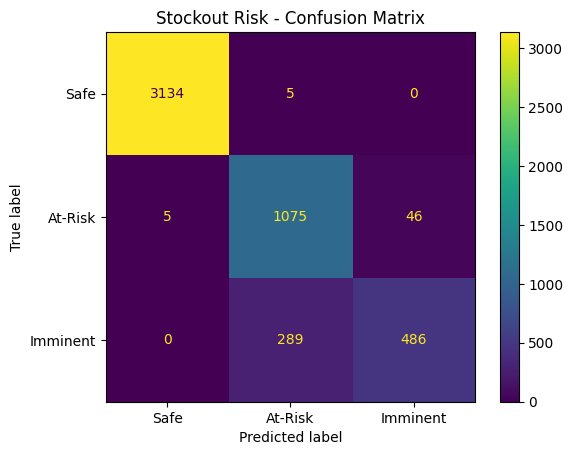

In [68]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Safe", "At-Risk", "Imminent"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Safe", "At-Risk", "Imminent"]
)

display_matrix.plot()
plt.title("Stockout Risk - Confusion Matrix")
plt.show()

                         Feature  Importance
6             num__days_of_cover    0.248475
7               num__reorder_gap    0.221031
8       num__days_of_cover_ratio    0.200141
0             num__opening_stock    0.055226
5         num__sales_velocity_7d    0.039540
3             num__reorder_point    0.039346
4   num__lead_time_days_expected    0.031688
9              num__day_of_month    0.028181
1            num__units_demanded    0.026642
2                num__units_sold    0.024110
10        num__is_recent_reorder    0.014275
12          cat__category_Bakery    0.006091
19         cat__category_Staples    0.005389
29   cat__popularity_tier_Medium    0.004638
23          cat__is_perishable_N    0.004357


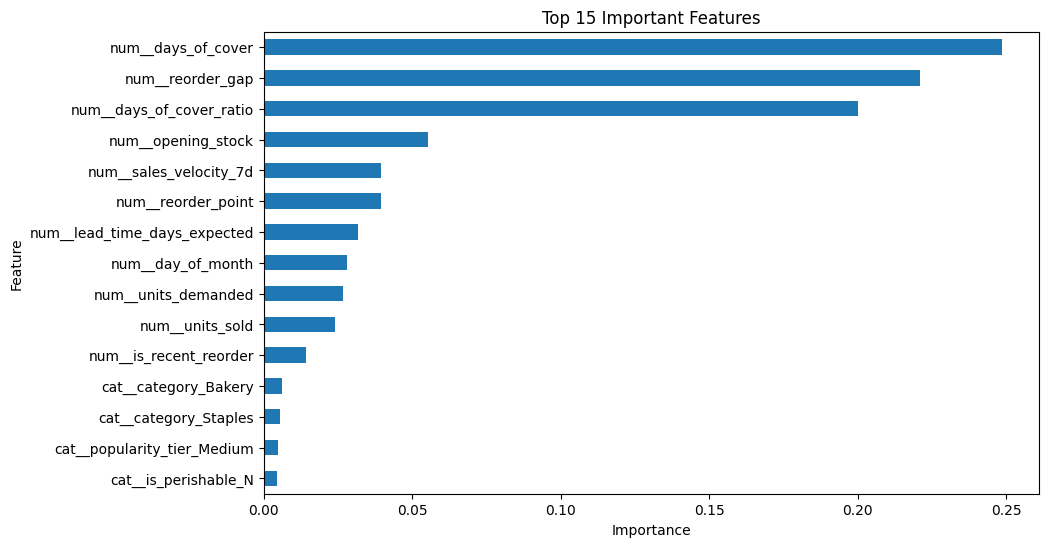

In [69]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
importance = model.named_steps["classifier"].feature_importances_

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Show top 15 important features
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).head(15)

print(importance_df)

# Create graph
importance_df.plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.show()

In [70]:
import joblib

joblib.dump(model, "quickcart_stockout_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [72]:
from google.colab import files

files.download("quickcart_stockout_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [73]:
print("QUICKCART STOCKOUT RISK PREDICTION")
print("-----------------------------------")
print("Project: Warehouse Inventory Stockout Risk")
print("Algorithm: Random Forest Classifier")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X_train.shape[1])
print("Model accuracy:", round(accuracy * 100, 2), "%")
print("Target classes:", list(y_train.unique()))
print("Status: Model trained and evaluated")

QUICKCART STOCKOUT RISK PREDICTION
-----------------------------------
Project: Warehouse Inventory Stockout Risk
Algorithm: Random Forest Classifier
Training records: 16560
Testing records: 5040
Number of features: 17
Model accuracy: 93.15 %
Target classes: ['Safe', 'At-Risk', 'Imminent']
Status: Model trained and evaluated


In [74]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     At-Risk       0.79      0.95      0.86      1126
    Imminent       0.91      0.63      0.74       775
        Safe       1.00      1.00      1.00      3139

    accuracy                           0.93      5040
   macro avg       0.90      0.86      0.87      5040
weighted avg       0.94      0.93      0.93      5040



In [75]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_test,
    y_pred,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv("quickcart_model_results.csv")

print("Project results saved successfully!")

Project results saved successfully!


In [76]:
from google.colab import files

files.download("quickcart_model_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [77]:
%%writefile README.md

# QuickCart Warehouse Inventory Stockout Risk Prediction

## Project Overview
This project predicts warehouse inventory stockout risk using Machine Learning.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

## Dataset
The project uses five CSV files:
1. dim_stores.csv
2. dim_skus.csv
3. dim_suppliers.csv
4. dim_events.csv
5. fact_inventory_daily.csv

## Machine Learning Algorithm
Random Forest Classifier

## Prediction Categories
- Safe
- At-Risk
- Imminent

## Project Steps
1. Data cleaning
2. Data merging
3. Feature engineering
4. Training and testing
5. Model evaluation
6. Feature importance analysis

## Output
The model predicts inventory stockout risk for warehouse products.

Writing README.md


In [78]:
!cat README.md


# QuickCart Warehouse Inventory Stockout Risk Prediction

## Project Overview
This project predicts warehouse inventory stockout risk using Machine Learning.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

## Dataset
The project uses five CSV files:
1. dim_stores.csv
2. dim_skus.csv
3. dim_suppliers.csv
4. dim_events.csv
5. fact_inventory_daily.csv

## Machine Learning Algorithm
Random Forest Classifier

## Prediction Categories
- Safe
- At-Risk
- Imminent

## Project Steps
1. Data cleaning
2. Data merging
3. Feature engineering
4. Training and testing
5. Model evaluation
6. Feature importance analysis

## Output
The model predicts inventory stockout risk for warehouse products.


In [79]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>